In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from utils import plot_ratemaps, rectify, construct_exponential, batch_inference

In [2]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

Gr = torch.load("Gr.pt", weights_only=True)
p0 = torch.load("p0.pt", weights_only=True) 

A, B, R = construct_exponential(sA, sB, Gr)

n_units = A.shape[0] # A.shape = B.shape, so
model = ExponentialRepresentation(A, B)

/home/m/Documents/phd/ESR/model.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A = torch.tensor(A, device=self.device, requires_grad=False)
/home/m/Documents/phd/ESR/model.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.B = torch.tensor(B, device=self.device, requires_grad=False)


In [3]:
torch.linalg.norm(p0, dim = -1)

tensor(21.5407, dtype=torch.float32)

In [4]:
# make dataset
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 10 
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)]
r = np.concatenate(r_batch)

In [5]:
p_ = batch_inference(model, r_batch, p0)

100%|██████████| 500/500 [00:32<00:00, 15.39it/s]


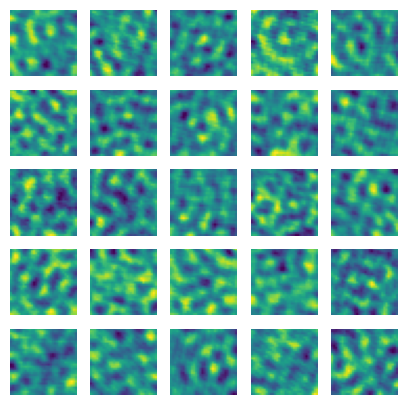

In [7]:
if rect:= False: # rectify or nay
    p = rectify(p_)
else:
    p = p_

ratemaps = plot_ratemaps(r[:,0], r[:,1], p, 5, figsize=(5,5), bins = 32)

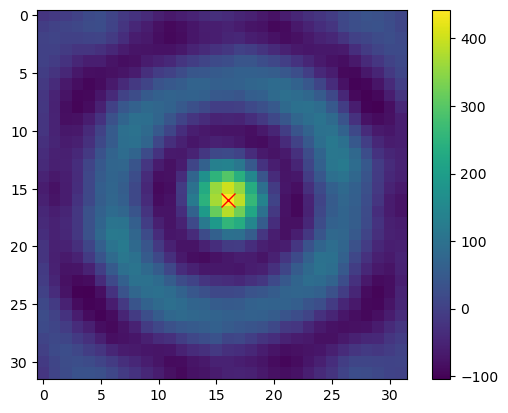

In [8]:
a = 16
diff = (ratemaps[:,a,a,None,None] - ratemaps)**2
prod = np.sum(ratemaps[:,a, a, None,None]*ratemaps, axis = 0)
plt.imshow(prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()

In [11]:
At, Bt, R = construct_exponential(sA, sB, Gr, s = 1.5)

In [12]:
transformed_model = ExponentialRepresentation(At, Bt)

In [ ]:
ns = 10000 # number of spatial samples
transformed_p0 = R.T@torch.tensor(np.ones(len(R)).astype(np.float32))
p_transformed = batch_inference(transformed_model, r_batch, transformed_p0) # run

100%|██████████| 500/500 [00:32<00:00, 15.39it/s]


AttributeError: 'numpy.ndarray' object has no attribute 'detach'

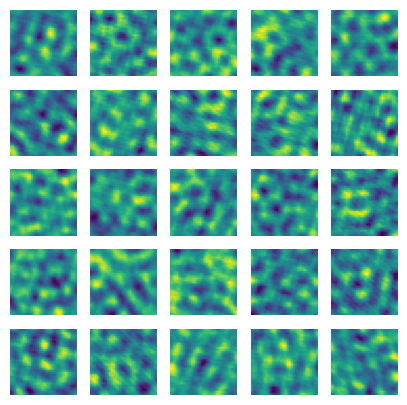

In [15]:
if rect:= False: # rectify or nay
    p_transformed = rectify(p_transformed)
else:
    p_transformed = p_transformed

transformed_ratemaps = plot_ratemaps(r[:,0], r[:,1], p_transformed, 5, figsize=(5,5), bins = 32)

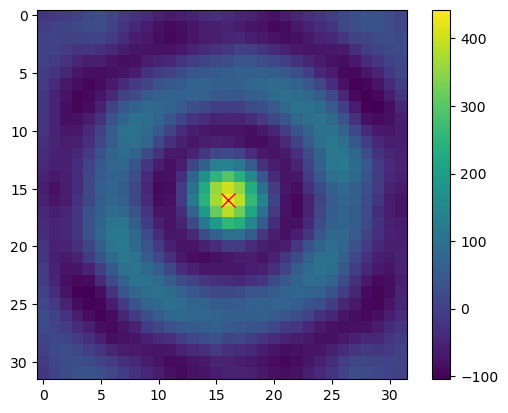

In [16]:
a = 16
transformed_prod = np.sum(transformed_ratemaps[:,a, a, None,None]*transformed_ratemaps, axis = 0)
plt.imshow(transformed_prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()

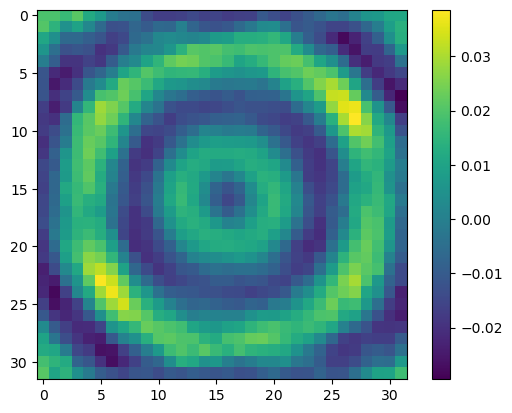

In [17]:
plt.imshow(transformed_prod.T - prod.T)  # difference in correlation structure b/a transform
plt.colorbar()

(array([ 3.,  7.,  2.,  3.,  8., 12., 11.,  9., 22., 16., 26., 34., 20.,
        33., 32., 27., 40., 19., 27., 27., 17., 22., 13.,  9.,  5.,  7.,
         5.,  4.,  1.,  0.,  0.,  3.]),
 array([-0.39225782, -0.36719981, -0.34214181, -0.3170838 , -0.2920258 ,
        -0.26696779, -0.24190979, -0.21685178, -0.19179378, -0.16673577,
        -0.14167777, -0.11661976, -0.09156176, -0.06650375, -0.04144575,
        -0.01638774,  0.00867026,  0.03372827,  0.05878627,  0.08384428,
         0.10890228,  0.13396029,  0.15901829,  0.1840763 ,  0.2091343 ,
         0.23419231,  0.25925031,  0.28430832,  0.30936632,  0.33442433,
         0.35948233,  0.38454034,  0.40959834]),
 <BarContainer object of 32 artists>)

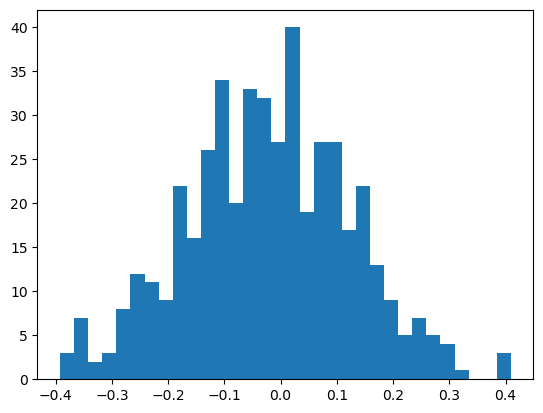

In [18]:
corrs = np.sum(ratemaps*transformed_ratemaps, axis = (1,2))/(np.linalg.norm(ratemaps, axis = (1,2))*np.linalg.norm(transformed_ratemaps, axis = (1,2)))
plt.hist(corrs, bins = 32)